## <span style="color:#1F4E79;">Optimization of the Bradley–Terry Likelihood</span>

This notebook compares different methods for fitting the Bradley–Terry model. We first use handcrafted optimizers and then reproduce the experiments using PyTorch. Every method is tested on the same simulated dataset.

In [15]:
# Import numerical, tabular, plotting and Bradley–Terry utilities.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from bradley_terry import *

##### Reusable Bradley–Terry Functions

| Function | Purpose |
|---|---|
| `center_parameters()` | Centres the parameters so that their mean is zero. |
| `generate_uniform_comparison_data()` | Simulates `(winner, loser)` observations. |
| `average_negative_log_likelihood()` | Calculates the average NLL on the complete dataset. |
| `parameter_recovery_error()` | Calculates RMSE between the true and estimated parameters. |
| `ford_condition_holds()` | Checks whether a finite Bradley–Terry MLE exists. |
| `optimize_with_full_batch_gradient_descent()` | Updates the parameters using the complete dataset. |
| `optimize_with_stochastic_gradient_descent()` | Updates the parameters using one observation at a time. |
| `optimize_with_minibatch_gradient_descent()` | Updates the parameters using small batches of observations. |
| `optimize_with_momentum_gradient_descent()` | Applies momentum to mini-batch gradient descent. |
| `optimize_with_adam()` | Uses Adam's adaptive first- and second-moment updates. |
| `OptimizationResult` | Stores the fitted parameters, optimization history and runtime. |

In [16]:
# Define settings shared by every optimizer.

SEED = 20260831
NUMBER_OF_ITEMS = 10
NUMBER_OF_COMPARISONS = 10_000
MINIBATCH_SIZE = 128
GRADIENT_TOLERANCE = 1e-6

rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)

experiment_settings = pd.DataFrame({
    "Setting": [
        "Random seed",
        "Number of items",
        "Number of comparisons",
        "Mini-batch size",
        "Full-gradient tolerance",
    ],
    "Value": [
        str(SEED),
        str(NUMBER_OF_ITEMS),
        f"{NUMBER_OF_COMPARISONS:,}",
        str(MINIBATCH_SIZE),
        f"{GRADIENT_TOLERANCE:.1e}",
    ],
})

experiment_settings

,Setting,Value
0,Random seed,20260831
1,Number of items,10
2,Number of comparisons,"10,000"
3,Mini-batch size,128
4,Full-gradient tolerance,1.0e-06


### Common Dataset
We generate one Bradley–Terry dataset and keep it fixed throughout the notebook. Every optimizer therefore receives the same observations and starts from the same zero parameter vector.

In [17]:
# Generate one fixed dataset for all optimization experiments.

item_names = [
    f"Item {item_index}"
    for item_index in range(NUMBER_OF_ITEMS)
]

true_parameters = center_parameters(
    rng.normal(
        loc=0.0,
        scale=0.8,
        size=NUMBER_OF_ITEMS,
    )
)

comparisons = generate_uniform_comparison_data(
    true_parameters=true_parameters,
    number_of_comparisons=NUMBER_OF_COMPARISONS,
    rng=rng,
)

true_parameter_table = pd.DataFrame({
    "Item": item_names,
    "True parameter": true_parameters,
})

print(f"Number of observations: {len(comparisons):,}")
print(f"First five observations: {comparisons[:5]}")
print(
    "Ford's condition holds:",
    ford_condition_holds(
        NUMBER_OF_ITEMS,
        comparisons,
    ),
)

true_parameter_table.style.format({
    "True parameter": "{:.4f}",
})

Number of observations: 10,000
First five observations: [(1, 4), (8, 9), (0, 8), (0, 4), (3, 7)]
Ford's condition holds: True


,Item,True parameter
0,Item 0,0.0499
1,Item 1,0.0969
2,Item 2,0.4827
3,Item 3,1.5604
4,Item 4,-0.3540
5,Item 5,-1.1734
6,Item 6,-0.1724
7,Item 7,0.0065
8,Item 8,-0.5966
9,Item 9,0.0999


In [4]:
# Summarize item appearances and verify Ford's condition.

comparison_array = np.asarray(
    comparisons,
    dtype=int,
)

wins = np.bincount(
    comparison_array[:, 0],
    minlength=NUMBER_OF_ITEMS,
)

losses = np.bincount(
    comparison_array[:, 1],
    minlength=NUMBER_OF_ITEMS,
)

appearances = wins + losses
empirical_win_rates = wins / appearances

comparison_summary_table = pd.DataFrame({
    "item": item_names,
    "true_parameter": true_parameters,
    "wins": wins,
    "losses": losses,
    "appearances": appearances,
    "empirical_win_rate": empirical_win_rates,
})

print(
    "Ford's condition holds:",
    ford_condition_holds(
        NUMBER_OF_ITEMS,
        comparisons,
    ),
)

comparison_summary_table

Ford's condition holds: True


,item,true_parameter,wins,losses,appearances,empirical_win_rate
0,Item 0,0.04995,1033,958,1991,0.51883
1,Item 1,0.09685,1028,927,1955,0.52583
2,Item 2,0.48274,1267,793,2060,0.61505
3,Item 3,1.56037,1702,309,2011,0.84635
4,Item 4,-0.35400,838,1133,1971,0.42516
5,Item 5,-1.17337,467,1567,2034,0.22960
6,Item 6,-0.17237,869,1093,1962,0.44292
7,Item 7,0.00647,1038,934,1972,0.52637
8,Item 8,-0.59657,712,1309,2021,0.35230
9,Item 9,0.09993,1046,977,2023,0.51705


### Experiment 1: Handcrafted Full-Batch Gradient Descent

In [18]:
# Fit the model using convergence-driven handcrafted full-batch GD.

full_batch_learning_rate = 0.1

full_batch_result = optimize_with_full_batch_gradient_descent(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=full_batch_learning_rate,
    gradient_tolerance=GRADIENT_TOLERANCE,
)

full_batch_recovery_error = parameter_recovery_error(
    true_parameters,
    full_batch_result.parameters,
)

final_gradient_norm = float(
    full_batch_result.gradient_norm_history[-1]
)

full_batch_converged = (
    final_gradient_norm <= GRADIENT_TOLERANCE
)

full_batch_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Gradient tolerance",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Final gradient norm",
        "Converged",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{full_batch_learning_rate:.4f}",
        f"{GRADIENT_TOLERANCE:.4e}",
        f"{full_batch_result.nll_history[0]:.4f}",
        f"{full_batch_result.nll_history[-1]:.4f}",
        f"{full_batch_recovery_error:.4f}",
        f"{full_batch_result.epochs_completed:,}",
        f"{int(full_batch_result.update_count_history[-1]):,}",
        f"{final_gradient_norm:.4e}",
        str(full_batch_converged),
        full_batch_result.stopping_reason,
        f"{full_batch_result.runtime_seconds:.4f}",
        f"{full_batch_result.parameters.sum():.4e}",
    ],
})

full_batch_summary

,Quantity,Value
0,Learning rate,0.1000
1,Gradient tolerance,1.0000e-06
2,Initial NLL,0.6931
3,Final NLL,0.5982
4,Parameter-recovery RMSE,0.0383
5,Epochs completed,"3,706"
6,Parameter updates,"3,706"
7,Final gradient norm,9.9908e-07
8,Converged,True
9,Stopping reason,gradient tolerance reached


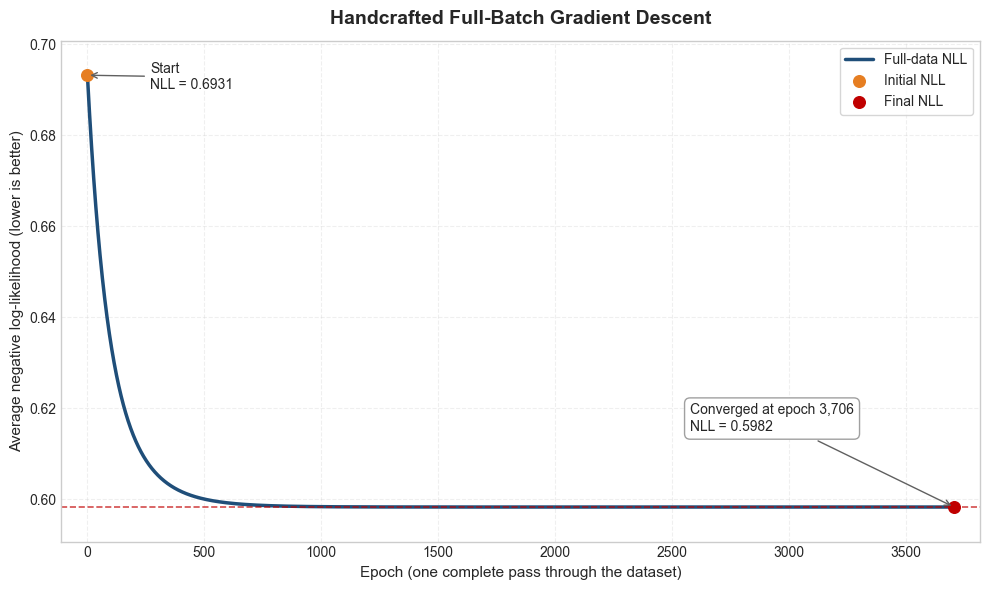

In [19]:
# Plot the full-data NLL during handcrafted full-batch optimization.

full_batch_nll_history = np.asarray(
    full_batch_result.nll_history,
    dtype=float,
)

full_batch_epochs = np.arange(
    len(full_batch_nll_history)
)

initial_nll = full_batch_nll_history[0]
final_nll = full_batch_nll_history[-1]
stopping_epoch = full_batch_result.epochs_completed

figure, axis = plt.subplots(figsize=(10, 6))

axis.plot(
    full_batch_epochs,
    full_batch_nll_history,
    color="#1F4E79",
    linewidth=2.5,
    label="Full-data NLL",
)

axis.scatter(
    0,
    initial_nll,
    color="#E67E22",
    s=70,
    zorder=3,
    label="Initial NLL",
)

axis.scatter(
    stopping_epoch,
    final_nll,
    color="#C00000",
    s=70,
    zorder=3,
    label="Final NLL",
)

axis.axhline(
    final_nll,
    color="#C00000",
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
)

axis.annotate(
    f"Start\nNLL = {initial_nll:.4f}",
    xy=(0, initial_nll),
    xytext=(45, -10),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
)

axis.annotate(
    (
        f"Converged at epoch {stopping_epoch:,}\n"
        f"NLL = {final_nll:.4f}"
    ),
    xy=(stopping_epoch, final_nll),
    xytext=(-190, 55),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Average negative log-likelihood (lower is better)",
    fontsize=11,
)

axis.set_title(
    "Handcrafted Full-Batch Gradient Descent",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.03, y=0.08)

plt.tight_layout()
plt.show()

#### Convergence check
To show that the gradient norm is falling below the selected gradient tolerance and has converged.

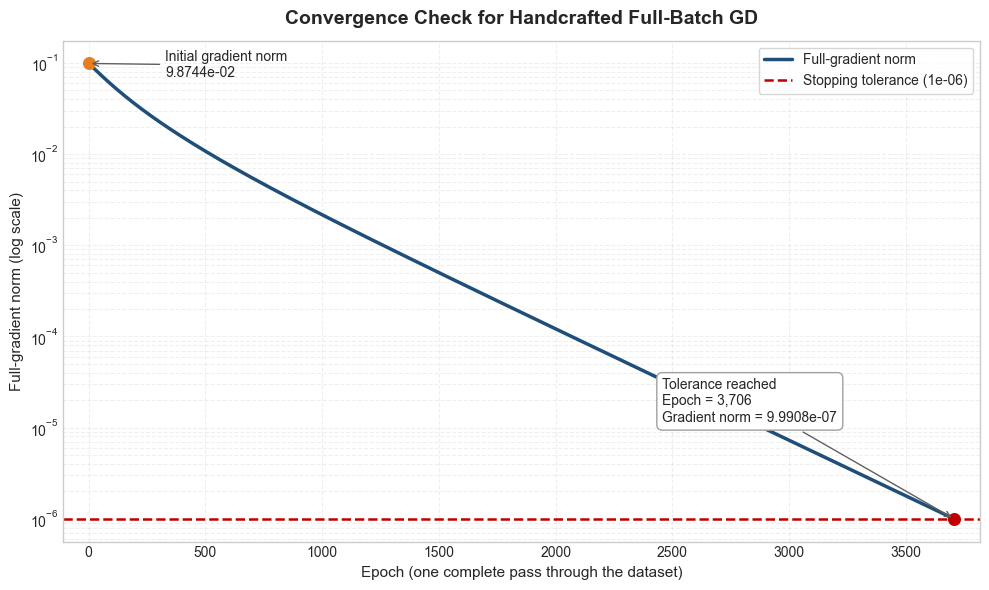

In [20]:
# Plot the full-gradient norm and the stopping tolerance.

gradient_norm_history = np.asarray(
    full_batch_result.gradient_norm_history,
    dtype=float,
)

gradient_epochs = np.arange(
    len(gradient_norm_history)
)

initial_gradient_norm = gradient_norm_history[0]
final_gradient_norm = gradient_norm_history[-1]
stopping_epoch = full_batch_result.epochs_completed

figure, axis = plt.subplots(figsize=(10, 6))

axis.semilogy(
    gradient_epochs,
    gradient_norm_history,
    color="#1F4E79",
    linewidth=2.5,
    label="Full-gradient norm",
)

axis.axhline(
    y=GRADIENT_TOLERANCE,
    color="#C00000",
    linestyle="--",
    linewidth=1.8,
    label=(
        "Stopping tolerance "
        f"({GRADIENT_TOLERANCE:.0e})"
    ),
)

axis.scatter(
    0,
    initial_gradient_norm,
    color="#E67E22",
    s=70,
    zorder=3,
)

axis.scatter(
    stopping_epoch,
    final_gradient_norm,
    color="#C00000",
    s=70,
    zorder=3,
)

axis.annotate(
    (
        f"Initial gradient norm\n"
        f"{initial_gradient_norm:.4e}"
    ),
    xy=(0, initial_gradient_norm),
    xytext=(55, -10),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
)

axis.annotate(
    (
        f"Tolerance reached\n"
        f"Epoch = {stopping_epoch:,}\n"
        f"Gradient norm = {final_gradient_norm:.4e}"
    ),
    xy=(stopping_epoch, final_gradient_norm),
    xytext=(-210, 70),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Full-gradient norm (log scale)",
    fontsize=11,
)

axis.set_title(
    "Convergence Check for Handcrafted Full-Batch GD",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.03)

plt.tight_layout()
plt.show()